# 06 - Check of the paper's selection criterion

The paper's simplified criterion (Eq. 2) says that combination treatment enriches the resistant strain
when

(1 − c)(1 − β_min) > (1 − α)/γ

It is derived for saturating antibiotic and inhibitor, before the antibiotic has been degraded. Its
exact parent, Eq. 1, is verified against the code in notebook 00. Here Eq. 2 is compared with
simulations on the α × β_min × c grid at the top of the paper's dose range (a0 = 100, i = 10).

Two read-outs of "did R gain?" are used, because they answer different questions:

- **During treatment (t = 100):** the sign of the change in ln(R/S) at t = 100, when the antibiotic is
  still above 1 in about two thirds of the strains. This is the regime the criterion describes, and is close to the paper's own protocol, which
  reads composition while the population is still suppressed.
- **After full regrowth (steady state):** the sign of the change once the drug has gone and the
  culture has regrown. This adds the regrowth phase, in which S always has the advantage.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import DEFAULT_PARAMS, hill
from src.analysis import sweep_engine as engine
from src.analysis.plotting import OKABE_ITO, heatmap_slices

df = pd.read_csv(TABLES / "grid_criterion_a0_100.csv")
gamma = DEFAULT_PARAMS.gamma
df["x_val"] = (1 - df.alpha) / gamma
df["y_val"] = (1 - df.c) * (1 - df.beta_min)
df["margin"] = df.y_val - df.x_val
df["criterion_R"] = df.margin > 0
df["sim_R_final"] = df.delta_log_ratio > 0
print(f"{len(df):,} strains; a0 = {df.a0.iloc[0]:g}, i = {df.i.iloc[0]:g}; γ = {gamma}")
print(f"Criterion predicts R enriched in {df.criterion_R.mean():.1%} of strains")

9,261 strains; a0 = 100, i = 10; γ = 1.38
Criterion predicts R enriched in 68.5% of strains


## Read-out during treatment (t = 100)

One extra fixed-horizon run per strain (cached in `criterion_readout_t100.csv`).

In [2]:
path = TABLES / "criterion_readout_t100.csv"
if path.exists():
    ro = pd.read_csv(path)
else:
    rows = []
    for a, b, c in zip(df.alpha, df.beta_min, df.c):
        tr = engine.integrate(replace(DEFAULT_PARAMS, alpha=a, beta_min=b, c=c), 100.0, 10.0,
                              stages=((100.0, 5.0),), adaptive=False)
        rows.append({"alpha": a, "beta_min": b, "c": c,
                     "delta_log_ratio_t100": (tr.ln_nr[-1] - tr.ln_ns[-1]) - (tr.ln_nr[0] - tr.ln_ns[0]),
                     "total_t100": tr.ns[-1] + tr.nr[-1], "a_t100": tr.a[-1]})
    ro = pd.DataFrame(rows)
    ro.to_csv(path, index=False, float_format="%.8g")
df = df.merge(ro, on=["alpha", "beta_min", "c"])
df["sim_R_t100"] = df.delta_log_ratio_t100 > 0
print(f"At t = 100 the population is still suppressed (total < 1) in {(df.total_t100 < 1).mean():.1%} of strains; "
      f"antibiotic still above 1 in {(df.a_t100 > 1).mean():.1%}")

At t = 100 the population is still suppressed (total < 1) in 65.5% of strains; antibiotic still above 1 in 65.3%


## Agreement

In [3]:
def agreement(truth):
    agree = (df.criterion_R == df[truth]).mean()
    over = (df.criterion_R & ~df[truth]).sum()      # criterion says R, simulation says S
    under = (~df.criterion_R & df[truth]).sum()     # criterion says S, simulation says R
    return {"agreement": f"{agree:.2%}", "criterion says R, simulation says S": int(over),
            "criterion says S, simulation says R": int(under)}
table = pd.DataFrame({"during treatment (t = 100)": agreement("sim_R_t100"),
                      "after full regrowth": agreement("sim_R_final")}).T
table

,agreement,"criterion says R, simulation says S","criterion says S, simulation says R"
during treatment (t = 100),99.20%,0,74
after full regrowth,93.69%,564,20


## Where the mismatches sit

`margin` = (1 − c)(1 − β_min) − (1 − α)/γ is the signed distance from the criterion's boundary.

In [4]:
for name, truth in [("during treatment", "sim_R_t100"), ("after full regrowth", "sim_R_final")]:
    over, under = df[df.criterion_R & ~df[truth]], df[~df.criterion_R & df[truth]]
    msg = f"{name}: "
    msg += (f"criterion-says-R mismatches have margin {over.margin.min():.4f} to {over.margin.max():.4f}; " if len(over) else "no criterion-says-R mismatches; ")
    msg += (f"criterion-says-S mismatches have margin {under.margin.min():.4f} to {under.margin.max():.4f}, "
            f"c from {under.c.min():g} to {under.c.max():g}, α from {under.alpha.min():g} to {under.alpha.max():g}" if len(under) else "no criterion-says-S mismatches")
    print(msg)
iota = float(hill(10.0, DEFAULT_PARAMS.h_i))
print(f"\nAt i = 10 the inhibitor effect is ι = {iota:.4f}, not exactly 1 as Eq. 2 assumes, so at c = 1 R keeps a "
      f"residual private benefit (1 − β_min) × {1 - iota:.4f}.")

bins = [-1, -0.1, -0.05, -0.02, 0, 0.02, 0.05, 0.1, 0.2, 1.01]
df["margin_bin"] = pd.cut(df.margin, bins)
by_margin = df.groupby("margin_bin", observed=True).agg(
    strains=("margin", "size"),
    mismatch_during_treatment=("sim_R_t100", lambda s: (s != df.loc[s.index, "criterion_R"]).mean()),
    mismatch_after_regrowth=("sim_R_final", lambda s: (s != df.loc[s.index, "criterion_R"]).mean()))
by_margin.round(3)

during treatment: no criterion-says-R mismatches; criterion-says-S mismatches have margin -0.0091 to 0.0000, c from 0.35 to 1, α from 0.75 to 1
after full regrowth: criterion-says-R mismatches have margin 0.0003 to 0.0688; criterion-says-S mismatches have margin 0.0000 to 0.0000, c from 1 to 1, α from 1 to 1

At i = 10 the inhibitor effect is ι = 0.9901, not exactly 1 as Eq. 2 assumes, so at c = 1 R keeps a residual private benefit (1 − β_min) × 0.0099.


,strains,mismatch_during_treatment,mismatch_after_regrowth
margin_bin,,,
"(-1.0, -0.1]",835,0.000,0.000
"(-0.1, -0.05]",926,0.000,0.000
"(-0.05, -0.02]",647,0.000,0.000
"(-0.02, 0.0]",513,0.144,0.039
"(0.0, 0.02]",403,0.000,0.759
"(0.02, 0.05]",574,0.000,0.387
"(0.05, 0.1]",804,0.000,0.045
"(0.1, 0.2]",1268,0.000,0.000
"(0.2, 1.01]",3291,0.000,0.000


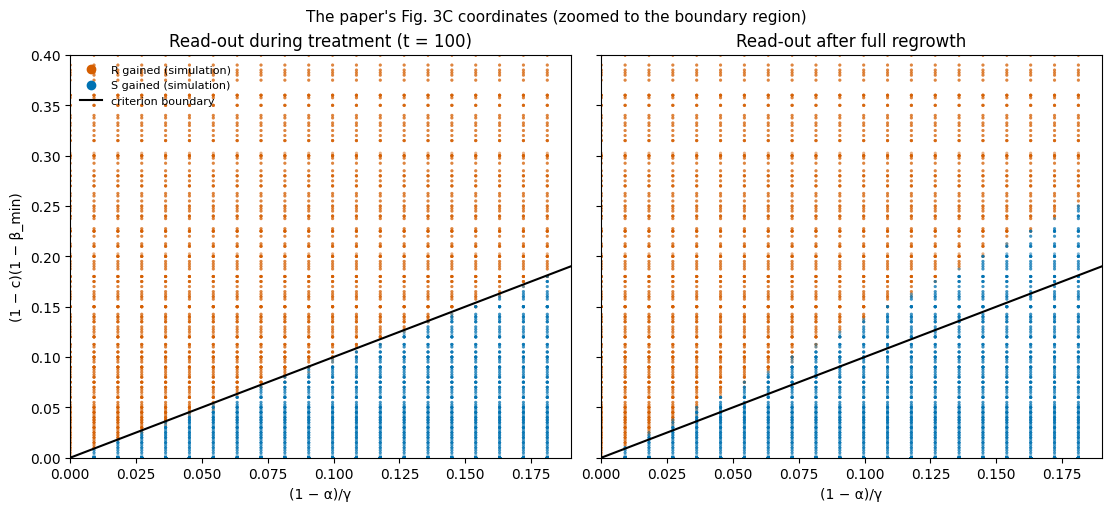

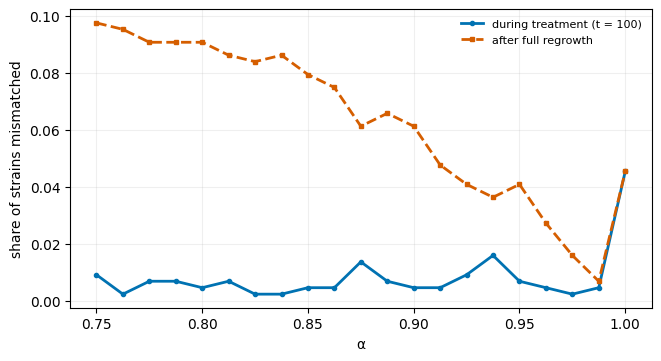

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True, sharey=True)
for ax, truth, name in zip(axes, ["sim_R_t100", "sim_R_final"], ["during treatment (t = 100)", "after full regrowth"]):
    col = np.where(df[truth], OKABE_ITO["vermillion"], OKABE_ITO["blue"])
    ax.scatter(df.x_val, df.y_val, c=col, s=5, alpha=0.5, lw=0)
    ax.plot([0, 0.2], [0, 0.2], color="black", lw=1.5)
    ax.set(xlim=(0, 0.19), ylim=(0, 0.4), xlabel="(1 − α)/γ", title=f"Read-out {name}")
axes[0].set_ylabel("(1 − c)(1 − β_min)")
handles = [plt.Line2D([], [], marker="o", ls="", color=OKABE_ITO["vermillion"], label="R gained (simulation)"),
           plt.Line2D([], [], marker="o", ls="", color=OKABE_ITO["blue"], label="S gained (simulation)"),
           plt.Line2D([], [], color="black", label="criterion boundary")]
axes[0].legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
fig.suptitle("The paper's Fig. 3C coordinates (zoomed to the boundary region)", fontsize=11)
plt.show()

df["mismatch_final"] = df.criterion_R != df.sim_R_final
df["mismatch_t100"] = df.criterion_R != df.sim_R_t100
by_alpha = df.groupby("alpha")[["mismatch_t100", "mismatch_final"]].mean()
fig, ax = plt.subplots(figsize=(6.5, 3.5), constrained_layout=True)
ax.plot(by_alpha.index, by_alpha.mismatch_t100, color=OKABE_ITO["blue"], lw=2, marker="o", ms=3, label="during treatment (t = 100)")
ax.plot(by_alpha.index, by_alpha.mismatch_final, color=OKABE_ITO["vermillion"], lw=2, ls="--", marker="s", ms=3, label="after full regrowth")
ax.set(xlabel="α", ylabel="share of strains mismatched"); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.2)
plt.show()

## Conclusion

- **For the regime it describes, the criterion is right.** Read during treatment (t = 100), Eq. 2
  agrees with the simulation for 99.2% of the 9,261 strains. All 74 mismatches lie within 0.01 of the
  boundary on the "criterion says S" side. They come from the inhibitor effect being ι = 0.990 at
  i = 10 instead of exactly 1, which leaves R a small residual private benefit that Eq. 2 under-counts
  (as zero when c = 1). At t = 100 the antibiotic is still above 1 in 65% of strains; the other 35%
  have already regrown, and all of those lie far from the boundary (margin ≥ 0.18).
- **After full regrowth the agreement is 93.7%, and the criterion over-predicts R.** In 564 strains the
  criterion says R is enriched but S ends ahead; all have a margin between 0 and 0.07. The reason is
  the regrowth phase: once the antibiotic has gone, S outgrows R by the burden (1 − α), which reverses
  a small advantage gained during treatment. The mismatch rate rises as α falls (about 10% of strains
  at α = 0.75). This comparison is a plain-model result: in all 564 strains both populations fall far
  below one cell before regrowing, and with the extinction floor every one is "community eradicated".
- **Away from the boundary both read-outs agree with the criterion without exception** (|margin| > 0.1).
- **Practical use.** Eq. 2 is a reliable quick screen for the direction of selection under a
  saturating dose. Within about 0.07 of its boundary, run the simulation, and decide beforehand whether
  the question is about composition during treatment or after regrowth.
- **Differences from the paper's own check.** The paper scanned doses and took the lowest resistant
  fraction among those that suppressed the population; here one dose (a0 = 100, i = 10) is used. An
  earlier version of this check on a 41 × 41 × 41 grid gave 93.5% after regrowth, consistent with the
  93.7% found here.